# Notebook 3: Comparing Predictions with Experimental Data

## Learning Objectives

1. Load experimental gene essentiality data
2. Compare model predictions with experiments
3. Calculate comparison metrics (precision, recall, accuracy)
4. Visualize agreements and disagreements
5. Interpret discrepancies between model and experiments

## Why Compare with Experiments?

Model validation is critical:
- **Validate** the model's predictive power
- **Identify** model limitations
- **Refine** the model based on discrepancies
- **Guide** experimental design

---

In [1]:
import sys
sys.path.insert(0, '..')

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib_venn import venn2
%matplotlib inline

print("✓ Libraries imported!")

✓ Libraries imported!


## Step 1: Load Model Predictions

We'll load the essentiality results from Notebook 2.

In [2]:
# Load predicted essentiality results
predicted_df = pd.read_csv('../results/essentiality/gene_essentiality_default_medium.csv')

print(f"Loaded {len(predicted_df)} gene predictions")
print(f"Essential (predicted): {predicted_df['is_essential'].sum()}")

# Get set of predicted essential genes
predicted_essential = set(predicted_df[predicted_df['is_essential']]['gene_id'])

Loaded 1054 gene predictions
Essential (predicted): 166


## Step 2: Load Experimental Data

**Note**: You need to provide experimental data in CSV format with columns:
- `gene_id`: Gene identifier
- `is_essential`: True/False or 1/0

For this demonstration, we'll show how to load and use such data.

In [3]:
# Example: Load experimental data
# experimental_df = pd.read_csv('../data/experimental/gene_essentiality_experimental.csv')
# experimental_essential = set(experimental_df[experimental_df['is_essential']]['gene_id'])

# For demonstration, we'll create a mock dataset
# In real use, replace this with actual experimental data
import random
random.seed(42)

# Simulate experimental data with some overlap with predictions
experimental_essential = set(random.sample(list(predicted_essential), 
                                          int(len(predicted_essential) * 0.7)))
experimental_essential.update(random.sample(
    list(set(predicted_df['gene_id']) - predicted_essential),
    int(len(predicted_df) * 0.05)
))

print(f"\nExperimental essential genes: {len(experimental_essential)}")
print("\n⚠ Note: Using simulated data for demonstration.")
print("   Replace with real experimental data for actual analysis.")


Experimental essential genes: 168

⚠ Note: Using simulated data for demonstration.
   Replace with real experimental data for actual analysis.


## Step 3: Calculate Comparison Metrics

We'll calculate:
- **True Positives (TP)**: Correctly predicted essential
- **False Positives (FP)**: Predicted essential but not essential
- **True Negatives (TN)**: Correctly predicted non-essential
- **False Negatives (FN)**: Predicted non-essential but actually essential

From these we calculate:
- **Precision**: TP / (TP + FP) - How many predicted essentials are correct?
- **Recall (Sensitivity)**: TP / (TP + FN) - How many actual essentials did we find?
- **Accuracy**: (TP + TN) / Total - Overall correctness

In [4]:
# Calculate overlap
true_positives = predicted_essential & experimental_essential
false_positives = predicted_essential - experimental_essential
false_negatives = experimental_essential - predicted_essential
true_negatives = (set(predicted_df['gene_id']) - predicted_essential - experimental_essential)

TP = len(true_positives)
FP = len(false_positives)
FN = len(false_negatives)
TN = len(true_negatives)

print("Confusion Matrix:")
print("=" * 40)
print(f"True Positives (TP):   {TP}")
print(f"False Positives (FP):  {FP}")
print(f"False Negatives (FN):  {FN}")
print(f"True Negatives (TN):   {TN}")

# Calculate metrics
precision = TP / (TP + FP) if (TP + FP) > 0 else 0
recall = TP / (TP + FN) if (TP + FN) > 0 else 0
accuracy = (TP + TN) / (TP + TN + FP + FN) if (TP + TN + FP + FN) > 0 else 0
f1_score = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0

print("\nPerformance Metrics:")
print("=" * 40)
print(f"Precision: {precision:.3f} ({precision*100:.1f}%)")
print(f"Recall:    {recall:.3f} ({recall*100:.1f}%)")
print(f"Accuracy:  {accuracy:.3f} ({accuracy*100:.1f}%)")
print(f"F1 Score:  {f1_score:.3f}")

Confusion Matrix:
True Positives (TP):   116
False Positives (FP):  50
False Negatives (FN):  52
True Negatives (TN):   836

Performance Metrics:
Precision: 0.699 (69.9%)
Recall:    0.690 (69.0%)
Accuracy:  0.903 (90.3%)
F1 Score:  0.695


## Step 4: Visualize with Venn Diagram

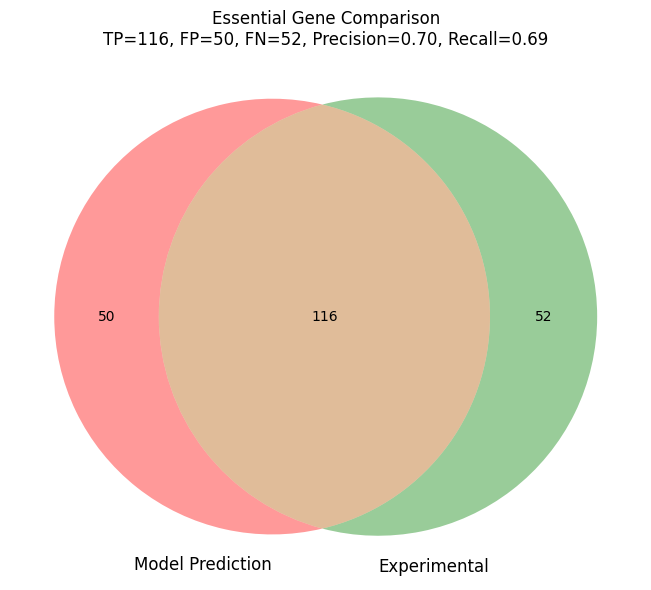

In [5]:
# Create Venn diagram
plt.figure(figsize=(8, 6))
venn2([predicted_essential, experimental_essential], 
      set_labels=('Model Prediction', 'Experimental'))
plt.title(f'Essential Gene Comparison\n'
          f'TP={TP}, FP={FP}, FN={FN}, Precision={precision:.2f}, Recall={recall:.2f}')
plt.tight_layout()
plt.show()

## Step 5: Examine Discrepancies

Let's look at genes where model and experiment disagree.

In [6]:
print("False Positives (predicted essential, but not in experiments):")
print(f"Total: {len(false_positives)}")
if len(false_positives) > 0:
    print("First 10 examples:")
    for i, gene in enumerate(list(false_positives)[:10]):
        print(f"  {i+1}. {gene}")

print("\nFalse Negatives (not predicted, but essential in experiments):")
print(f"Total: {len(false_negatives)}")
if len(false_negatives) > 0:
    print("First 10 examples:")
    for i, gene in enumerate(list(false_negatives)[:10]):
        print(f"  {i+1}. {gene}")

False Positives (predicted essential, but not in experiments):
Total: 50
First 10 examples:
  1. {'PA4055'}
  2. {'PA4529'}
  3. {'PA0650'}
  4. {'PA4670'}
  5. {'PA3639'}
  6. {'PA3166'}
  7. {'PA1756'}
  8. {'PA5243'}
  9. {'PA5259'}
  10. {'PA2968'}

False Negatives (not predicted, but essential in experiments):
Total: 52
First 10 examples:
  1. {'PA0519'}
  2. {'PA2253'}
  3. {'PA0649'}
  4. {'PA2307'}
  5. {'PA2948'}
  6. {'PA3863'}
  7. {'PA2522'}
  8. {'PA0744'}
  9. {'PA1373'}
  10. {'PA1581'}


## Step 6: Growth Ratio Analysis

Let's see how growth ratios differ for correctly vs incorrectly predicted genes.

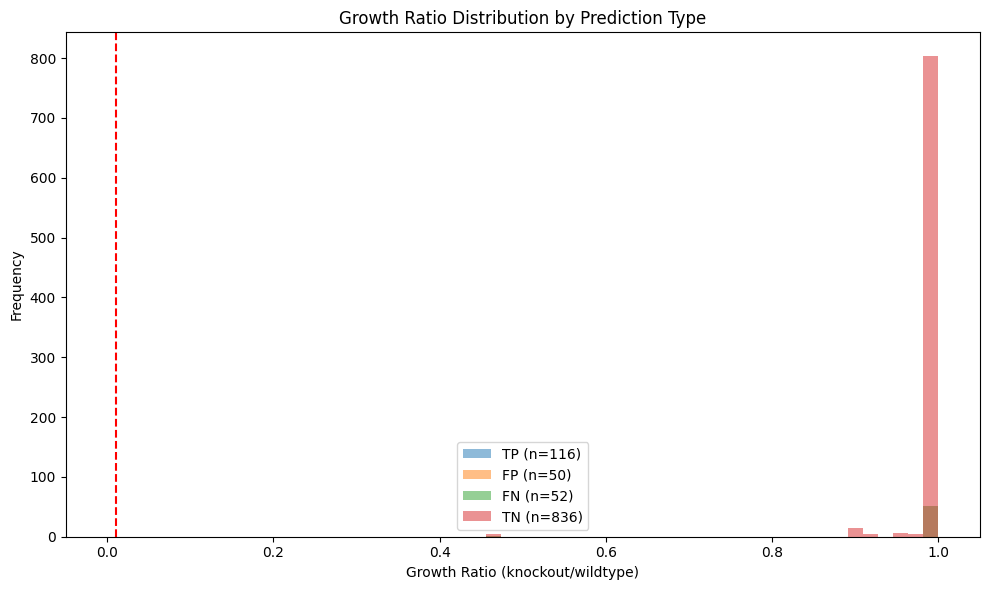

In [7]:
# Create categories
predicted_df['prediction_type'] = 'TN'  # Default

predicted_df.loc[
    predicted_df['gene_id'].isin(true_positives), 'prediction_type'
] = 'TP'

predicted_df.loc[
    predicted_df['gene_id'].isin(false_positives), 'prediction_type'
] = 'FP'

predicted_df.loc[
    predicted_df['gene_id'].isin(false_negatives), 'prediction_type'
] = 'FN'

# Plot distributions
fig, ax = plt.subplots(figsize=(10, 6))

for pred_type in ['TP', 'FP', 'FN', 'TN']:
    subset = predicted_df[predicted_df['prediction_type'] == pred_type]
    if len(subset) > 0:
        ax.hist(subset['growth_ratio'], bins=30, alpha=0.5, label=f'{pred_type} (n={len(subset)})')

ax.set_xlabel('Growth Ratio (knockout/wildtype)')
ax.set_ylabel('Frequency')
ax.set_title('Growth Ratio Distribution by Prediction Type')
ax.legend()
ax.axvline(x=0.01, color='red', linestyle='--', label='Threshold')
plt.tight_layout()
plt.show()

## Summary

In this notebook, you learned:

1. ✓ How to load and structure experimental data
2. ✓ How to compare model predictions with experiments
3. ✓ How to calculate validation metrics (precision, recall, accuracy)
4. ✓ How to visualize agreements and discrepancies
5. ✓ How to interpret differences between model and reality

### Understanding Discrepancies:

**False Positives** (predicted essential, but not experimental) may indicate:
- Model missing alternative pathways
- Incorrect GPR associations
- Medium differences between model and experiment

**False Negatives** (experimental essential, not predicted) may indicate:
- Missing reactions in the model
- Incomplete model reconstruction
- Regulatory effects not captured by FBA

### Key Takeaways:

- No model is perfect - validation helps identify gaps
- Metabolic models are constantly refined based on new data
- Combining computational and experimental approaches is powerful
- Context matters - essentiality depends on growth conditions

---